# Underwater YOLO — Held-Out Test Analysis and Paired Cluster Bootstrap (Colab v4)

This notebook performs the **common, independent held-out-test analysis** for the frozen four-model panel:

- **YOLO11m baseline** — matched baseline
- **CBAM before Detect** — validation-selected compromise candidate
- **DW-HDC-SPPF** — validation-selected compromise candidate
- **YOLO26m** — separate framework-level comparator

It reads the aligned `predictions_coco_ids.json` file from each model's `test-m` directory, evaluates every model with the same `faster-coco-eval` implementation, and calculates paired cluster-bootstrap confidence intervals using the leakage groups in `splits.csv`.

**Frozen interpretation rule:** test results are confirmatory. They must not be used to tune thresholds, substitute models, retrain checkpoints, or create a new test-selected ranking.

Run this notebook only after all four model-specific test notebooks have completed. The analysis itself is CPU-based; the latency values are copied from the four model notebooks, which must all use the same **NVIDIA RTX PRO 6000 Blackwell Server Edition**, test batch size, and inference settings.

## 0) Configuration

Packaging adaptation: open this notebook with the working directory set to its containing common-test-analysis folder. Inputs are supplied beside the notebook and under predictions/; outputs are written to results/. The Google Drive mount is no longer required. Calculations, analysis settings and recorded outputs are unchanged. Saved output text can therefore still show the original Drive locations.

RUNTIME_METRICS retains the measurements recorded by the model-specific test notebooks; this notebook does not measure model latency.


In [ ]:
from pathlib import Path

BASE_DIR = Path.cwd()
NOTEBOOK_DIR = BASE_DIR
OUTPUT_DIR = BASE_DIR / "results"

COCO_ANN_FILE = BASE_DIR / "instances_test2017.json"
SPLITS_FILE = NOTEBOOK_DIR / "splits.csv"
GROUP_MAP_FILE = OUTPUT_DIR / "test_image_groups.csv"

MODEL_RUNS = {
    "YOLO11m baseline": {
        "folder": "B0",
        "role": "Matched baseline",
    },
    "CBAM before Detect": {
        "folder": "A1",
        "role": "Validation-selected candidate",
    },
    "DW-HDC-SPPF": {
        "folder": "C2",
        "role": "Validation-selected candidate",
    },
    "YOLO26m": {
        "folder": "YOLO26m",
        "role": "Separate comparator",
    },
}

for settings in MODEL_RUNS.values():
    settings["predictions"] = (
        BASE_DIR / "predictions" / settings["folder"] / "predictions_coco_ids.json"
    )

MODEL_ORDER = list(MODEL_RUNS)
BASELINE_MODEL = "YOLO11m baseline"
COMPARISONS = [
    ("CBAM before Detect", BASELINE_MODEL),
    ("DW-HDC-SPPF", BASELINE_MODEL),
    ("YOLO26m", BASELINE_MODEL),
]

EXPECTED_IMAGES = 1662
EXPECTED_ANNOTATIONS = 9860
EXPECTED_CATEGORIES = 14
EXPECTED_GROUPS = 666

METRICS = {
    "AP_all": "AP@[0.50:0.95]",
    "AP_50": "AP@0.50",
    "AP_75": "AP@0.75",
    "AP_small": "AP-small",
    "AP_medium": "AP-medium",
    "AP_large": "AP-large",
    "AR_third": "AR@100",
    "AR_small": "AR-small",
    "AR_medium": "AR-medium",
    "AR_large": "AR-large",
}

# The primary metric and planned secondary metrics for paired uncertainty estimates.
BOOTSTRAP_METRICS = ["AP_all", "AP_50", "AP_75", "AP_small"]
N_BOOTSTRAPS = 2000
BOOTSTRAP_SEED = 20260824
CONFIDENCE_LEVEL = 0.95
SAVE_EVERY = 25

TEST_GPU = "NVIDIA RTX PRO 6000 Blackwell Server Edition"
TEST_BATCH = 128
INFERENCE_SETTINGS = {
    "imgsz": 640,
    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,
    "half": False,
    "augment": False,
}

# Values reported by the four completed test notebooks.
RUNTIME_METRICS = {
    "YOLO11m baseline": {
        "inference_ms": 1.33,
        "end_to_end_ms": 1.85,
        "parameters": 20_040_826,
        "gflops": 67.7,
    },
    "CBAM before Detect": {
        "inference_ms": 1.40,
        "end_to_end_ms": 1.90,
        "parameters": 20_116_211,
        "gflops": 67.8,
    },
    "DW-HDC-SPPF": {
        "inference_ms": 1.33,
        "end_to_end_ms": 1.84,
        "parameters": 20_048_506,
        "gflops": 67.7,
    },
    "YOLO26m": {
        "inference_ms": 1.32,
        "end_to_end_ms": 1.64,
        "parameters": 20_360_246,
        "gflops": 68.1,
    },
}

## 1) Check the packaged inputs

The shared ground truth and splits.csv are beside this notebook. Model predictions are stored in the four named subfolders under predictions/.


In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not COCO_ANN_FILE.is_file():
    raise FileNotFoundError(f"COCO ground truth not found: {COCO_ANN_FILE}")
if not SPLITS_FILE.is_file():
    raise FileNotFoundError(f"Split metadata not found: {SPLITS_FILE}")

print("Ground truth:", COCO_ANN_FILE)
print("Split metadata:", SPLITS_FILE)
print("Analysis output:", OUTPUT_DIR)

Mounted at /content/drive
Ground truth: /content/drive/MyDrive/UnderWaterYOLO11/instances_test2017.json
Split metadata: /content/drive/MyDrive/Colab Notebooks/Dissertation/test-set/splits.csv
Analysis output: /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis


## 2) Install and import the common evaluator

In [ ]:
%pip install "faster-coco-eval==1.7.2" -q --progress-bar on

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 587.9/587.9 kB 2.2 MB/s eta 0:00:00


In [ ]:
import json
import time
from collections import defaultdict

import faster_coco_eval
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from faster_coco_eval import COCO, COCOeval_faster
from IPython.display import display
from tqdm.auto import tqdm

if faster_coco_eval.__version__ != "1.7.2":
    raise RuntimeError(
        f"Expected faster-coco-eval 1.7.2, found {faster_coco_eval.__version__}"
    )

print("faster-coco-eval:", faster_coco_eval.__version__)
print("Test GPU recorded by all model notebooks:", TEST_GPU)
print("Test batch:", TEST_BATCH)
print("Inference settings:", INFERENCE_SETTINGS)

faster-coco-eval: 1.7.2
Test GPU recorded by all model notebooks: NVIDIA RTX PRO 6000 Blackwell Server Edition
Test batch: 128
Inference settings: {'imgsz': 640, 'conf': 0.001, 'iou': 0.7, 'max_det': 300, 'half': False, 'augment': False}


## 3) Load the ground truth and create the cluster mapping

The `splits.csv` dataset ID is not the same as the PyLabel-generated COCO image ID. The join is therefore performed by the unique image filename.

In [ ]:
with COCO_ANN_FILE.open("r", encoding="utf-8") as file:
    coco_ground_truth = json.load(file)

if len(coco_ground_truth["images"]) != EXPECTED_IMAGES:
    raise ValueError("Unexpected number of COCO test images")
if len(coco_ground_truth["annotations"]) != EXPECTED_ANNOTATIONS:
    raise ValueError("Unexpected number of COCO test annotations")
if len(coco_ground_truth["categories"]) != EXPECTED_CATEGORIES:
    raise ValueError("Unexpected number of COCO categories")

splits = pd.read_csv(SPLITS_FILE)
test_groups = splits.loc[
    splits["split"].eq("test"), ["image_rel_path", "group_id"]
].copy()
test_groups["file_name"] = test_groups["image_rel_path"].map(
    lambda path: Path(path).name
)
test_groups = test_groups[["file_name", "group_id"]]

coco_images = pd.DataFrame(coco_ground_truth["images"])[["id", "file_name"]]
coco_images["file_name"] = coco_images["file_name"].map(
    lambda path: Path(path).name
)
coco_images = coco_images.rename(columns={"id": "coco_image_id"})

if not coco_images["file_name"].is_unique:
    raise ValueError("COCO ground truth contains duplicate filenames")
if not test_groups["file_name"].is_unique:
    raise ValueError("Test split contains duplicate filenames")
if set(coco_images["file_name"]) != set(test_groups["file_name"]):
    raise ValueError("COCO ground truth and test split filenames do not match")

image_groups = coco_images.merge(
    test_groups,
    on="file_name",
    how="inner",
    validate="one_to_one",
)

if len(image_groups) != EXPECTED_IMAGES:
    raise ValueError("Incomplete image-to-group mapping")
if image_groups["group_id"].nunique() != EXPECTED_GROUPS:
    raise ValueError("Unexpected number of test leakage groups")

image_groups.to_csv(GROUP_MAP_FILE, index=False)

group_sizes = image_groups.groupby("group_id").size()
print(f"Images: {len(image_groups):,}")
print(f"Annotations: {len(coco_ground_truth['annotations']):,}")
print(f"Categories: {len(coco_ground_truth['categories'])}")
print(f"Leakage groups: {group_sizes.size}")
print(f"Largest group: {group_sizes.max()} images")
print("Saved mapping:", GROUP_MAP_FILE)
display(image_groups.head())

Images: 1,662
Annotations: 9,860
Categories: 14
Leakage groups: 666
Largest group: 210 images
Saved mapping: /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/test_image_groups.csv


,coco_image_id,file_name,group_id
0,0,006295.jpg,ruod_non_singleton:0006
1,1,007347.jpg,ruod_singleton:007347
2,2,Slano_Paralenz_Vaquita_4540.jpg,seaclear_site:Slano
3,3,006918.jpg,ruod_singleton:006918
4,4,004416.jpg,ruod_non_singleton:0006


## 4) Load and validate the four prediction files

This cell fails before evaluation if any model result is missing or incompatible. Zero-width or zero-height boundary-clipped predictions are reported but retained unchanged.

In [ ]:
missing_files = [
    f"{model}: {settings['predictions']}"
    for model, settings in MODEL_RUNS.items()
    if not settings["predictions"].is_file()
]
if missing_files:
    raise FileNotFoundError(
        "Missing packaged prediction files; check the extracted supplement folder:\n" + "\n".join(missing_files)
    )

valid_image_ids = {image["id"] for image in coco_ground_truth["images"]}
valid_category_ids = {
    category["id"] for category in coco_ground_truth["categories"]
}
coco_id_by_filename = {
    Path(image["file_name"]).name: image["id"]
    for image in coco_ground_truth["images"]
}

predictions_by_model = {}
validation_rows = []

for model, settings in MODEL_RUNS.items():
    with settings["predictions"].open("r", encoding="utf-8") as file:
        predictions = json.load(file)

    detections_per_image = defaultdict(int)
    degenerate_boxes = 0

    for prediction in predictions:
        required = {"image_id", "file_name", "category_id", "bbox", "score"}
        if not required.issubset(prediction):
            raise ValueError(f"{model} prediction is missing required fields")

        image_id = prediction["image_id"]
        category_id = prediction["category_id"]
        bbox = prediction["bbox"]
        score = prediction["score"]
        filename = Path(prediction["file_name"]).name

        if image_id not in valid_image_ids:
            raise ValueError(f"{model} contains an unknown image ID")
        if category_id not in valid_category_ids:
            raise ValueError(f"{model} contains an unknown category ID")
        if coco_id_by_filename.get(filename) != image_id:
            raise ValueError(f"{model} filename-to-image-ID mismatch")
        if len(bbox) != 4 or not np.isfinite(bbox).all():
            raise ValueError(f"{model} contains a malformed bounding box")
        if bbox[2] < 0 or bbox[3] < 0:
            raise ValueError(f"{model} contains a negative box dimension")
        if not np.isfinite(score) or not 0 <= score <= 1:
            raise ValueError(f"{model} contains an invalid score")

        if bbox[2] == 0 or bbox[3] == 0:
            degenerate_boxes += 1
        detections_per_image[image_id] += 1

    predictions_by_model[model] = [
        {
            "image_id": prediction["image_id"],
            "category_id": prediction["category_id"],
            "bbox": prediction["bbox"],
            "score": prediction["score"],
        }
        for prediction in predictions
    ]

    validation_rows.append(
        {
            "model": model,
            "role": settings["role"],
            "detections": len(predictions),
            "images_with_detections": len(detections_per_image),
            "images_without_detections": EXPECTED_IMAGES - len(detections_per_image),
            "degenerate_boxes_retained": degenerate_boxes,
            "maximum_detections_per_image": max(
                detections_per_image.values(), default=0
            ),
            "images_over_coco_maxdets_100": sum(
                count > 100 for count in detections_per_image.values()
            ),
        }
    )

prediction_validation = pd.DataFrame(validation_rows)
prediction_validation.to_csv(
    OUTPUT_DIR / "prediction_validation_summary.csv", index=False
)
display(prediction_validation)

,model,role,detections,images_with_detections,images_without_detections,degenerate_boxes_retained,maximum_detections_per_image,images_over_coco_maxdets_100
0,YOLO11m baseline,Matched baseline,26772,1660,2,18,300,32
1,CBAM before Detect,Validation-selected candidate,34981,1660,2,118,300,53
2,DW-HDC-SPPF,Validation-selected candidate,42133,1662,0,298,300,60
3,YOLO26m,Separate comparator,55882,1661,1,145,300,110


## 5) Common independent COCO evaluation

Every model is evaluated using the same ground truth, evaluator version, IoU thresholds, area ranges, and standard `maxDets=[1, 10, 100]`. Per-class AP is descriptive and is not used to select a model.

In [ ]:
def evaluate_predictions(ground_truth, predictions, include_per_class=False):
    silent = lambda *args, **kwargs: None
    coco_gt = COCO(
        ground_truth,
        use_deepcopy=True,
        print_function=silent,
    )
    coco_dt = coco_gt.loadRes(predictions, min_score=0.0)
    evaluator = COCOeval_faster(
        coco_gt,
        coco_dt,
        iouType="bbox",
        print_function=silent,
    )
    evaluator.params.maxDets = [1, 10, 100]
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    stats = {
        key: (np.nan if value < 0 else float(value))
        for key, value in evaluator.stats_as_dict.items()
    }

    class_rows = []
    if include_per_class:
        # precision dimensions: IoU, recall, category, area, maxDets
        precision = np.asarray(evaluator.eval["precision"])
        categories = sorted(
            ground_truth["categories"], key=lambda category: category["id"]
        )
        for category_index, category in enumerate(categories):
            values = precision[:, :, category_index, 0, -1]
            values = values[values > -1]
            class_rows.append(
                {
                    "category_id": category["id"],
                    "category": category["name"],
                    "AP_all": values.mean() if values.size else np.nan,
                }
            )

    return stats, class_rows

In [ ]:
point_rows = []
per_class_rows = []

for model in tqdm(MODEL_ORDER, desc="Common COCO evaluation"):
    stats, class_rows = evaluate_predictions(
        coco_ground_truth,
        predictions_by_model[model],
        include_per_class=True,
    )

    for metric_key, metric_label in METRICS.items():
        point_rows.append(
            {
                "model": model,
                "role": MODEL_RUNS[model]["role"],
                "metric": metric_key,
                "metric_label": metric_label,
                "value": stats[metric_key],
            }
        )

    for row in class_rows:
        row["model"] = model
        row["role"] = MODEL_RUNS[model]["role"]
        per_class_rows.append(row)

point_estimates = pd.DataFrame(point_rows)
per_class_ap = pd.DataFrame(per_class_rows)

point_estimates.to_csv(
    OUTPUT_DIR / "common_test_point_estimates.csv", index=False
)
per_class_ap.to_csv(OUTPUT_DIR / "common_test_per_class_ap.csv", index=False)

point_table = point_estimates.pivot(
    index="model", columns="metric_label", values="value"
).reindex(MODEL_ORDER)
point_table = point_table[[label for label in METRICS.values()]]

display(point_table.style.format("{:.4f}"))
display(
    per_class_ap.pivot(index="category", columns="model", values="AP_all")
    .reindex(columns=MODEL_ORDER)
    .style.format("{:.4f}")
)

Common COCO evaluation:   0%|          | 0/4 [00:00<?, ?it/s]

metric_label,AP@[0.50:0.95],AP@0.50,AP@0.75,AP-small,AP-medium,AP-large,AR@100,AR-small,AR-medium,AR-large
model,,,,,,,,,,
YOLO11m baseline,0.2932,0.4259,0.3090,0.1091,0.2263,0.3285,0.3890,0.1748,0.3059,0.4251
CBAM before Detect,0.3042,0.4427,0.3193,0.1133,0.2392,0.3376,0.4119,0.1940,0.3204,0.4431
DW-HDC-SPPF,0.3074,0.4502,0.3188,0.1154,0.2299,0.3414,0.4273,0.2099,0.3387,0.4579
YOLO26m,0.3018,0.4383,0.3205,0.1255,0.2397,0.3317,0.4303,0.2388,0.3465,0.4581


model,YOLO11m baseline,CBAM before Detect,DW-HDC-SPPF,YOLO26m
category,,,,
bivalve,0.0914,0.1548,0.1814,0.1156
bottle,0.1083,0.1290,0.1261,0.1273
cephalopod,0.6617,0.6656,0.6724,0.6564
container,0.0441,0.0509,0.0375,0.0377
diver,0.4836,0.5130,0.4933,0.5241
fish,0.3966,0.4000,0.3956,0.4107
jellyfish,0.5489,0.5541,0.5535,0.5287
net,0.0059,0.0169,0.0094,0.0079
rope,0.0046,0.0085,0.0100,0.0064


## 6) Latency and model complexity

Latency is compared descriptively because all four test notebooks use the same GPU, image size, batch size, precision, and inference settings. It is not cluster-bootstrapped: a confidence interval for runtime would require repeated timing measurements rather than resampling test-image groups.

In [ ]:
runtime_table = pd.DataFrame.from_dict(RUNTIME_METRICS, orient="index")
runtime_table.index.name = "model"
runtime_table = runtime_table.reindex(MODEL_ORDER)
runtime_table.insert(
    0,
    "role",
    [MODEL_RUNS[model]["role"] for model in runtime_table.index],
)
runtime_table["gpu"] = TEST_GPU
runtime_table["batch"] = TEST_BATCH

required_runtime_columns = [
    "inference_ms",
    "end_to_end_ms",
    "parameters",
    "gflops",
]
missing_runtime = runtime_table[required_runtime_columns].isna().any(axis=1)

if missing_runtime.any():
    print("Fill RUNTIME_METRICS in the configuration cell for:")
    for model in runtime_table.index[missing_runtime]:
        print(" -", model)
    print("Accuracy evaluation and bootstrap can still run.")
else:
    runtime_table["inference_fps"] = 1000.0 / runtime_table["inference_ms"]
    runtime_table["end_to_end_fps"] = 1000.0 / runtime_table["end_to_end_ms"]

    baseline = runtime_table.loc[BASELINE_MODEL]
    runtime_table["inference_delta_ms"] = (
        runtime_table["inference_ms"] - baseline["inference_ms"]
    )
    runtime_table["inference_delta_percent"] = (
        100.0
        * runtime_table["inference_delta_ms"]
        / baseline["inference_ms"]
    )
    runtime_table["end_to_end_delta_ms"] = (
        runtime_table["end_to_end_ms"] - baseline["end_to_end_ms"]
    )
    runtime_table["end_to_end_delta_percent"] = (
        100.0
        * runtime_table["end_to_end_delta_ms"]
        / baseline["end_to_end_ms"]
    )

runtime_table.to_csv(OUTPUT_DIR / "runtime_and_complexity.csv")
display(runtime_table)

,role,inference_ms,end_to_end_ms,parameters,gflops,gpu,batch,inference_fps,end_to_end_fps,inference_delta_ms,inference_delta_percent,end_to_end_delta_ms,end_to_end_delta_percent
model,,,,,,,,,,,,,
YOLO11m baseline,Matched baseline,1.33,1.85,20040826,67.7,NVIDIA RTX PRO 6000 Blackwell Server Edition,128,751.879699,540.540541,0.00,0.000000,0.00,0.000000
CBAM before Detect,Validation-selected candidate,1.40,1.90,20116211,67.8,NVIDIA RTX PRO 6000 Blackwell Server Edition,128,714.285714,526.315789,0.07,5.263158,0.05,2.702703
DW-HDC-SPPF,Validation-selected candidate,1.33,1.84,20048506,67.7,NVIDIA RTX PRO 6000 Blackwell Server Edition,128,751.879699,543.478261,0.00,0.000000,-0.01,-0.540541
YOLO26m,Separate comparator,1.32,1.64,20360246,68.1,NVIDIA RTX PRO 6000 Blackwell Server Edition,128,757.575758,609.756098,-0.01,-0.751880,-0.21,-11.351351


## 7) Prepare the paired cluster bootstrap

One bootstrap replicate samples all 666 leakage groups with replacement. Every selected group contributes all its images. If a group is selected more than once, its images, annotations, and predictions receive new temporary COCO IDs so that every occurrence contributes separately.

The same sampled groups are used for all four models, making the model differences paired.

In [ ]:
image_by_id = {
    image["id"]: image for image in coco_ground_truth["images"]
}

annotations_by_image = defaultdict(list)
for annotation in coco_ground_truth["annotations"]:
    annotations_by_image[annotation["image_id"]].append(annotation)

predictions_by_model_and_image = {}
for model, predictions in predictions_by_model.items():
    by_image = defaultdict(list)
    for prediction in predictions:
        by_image[prediction["image_id"]].append(prediction)
    predictions_by_model_and_image[model] = by_image

images_by_group = (
    image_groups.groupby("group_id")["coco_image_id"].apply(list).to_dict()
)
group_ids = np.array(sorted(images_by_group), dtype=object)

if len(group_ids) != EXPECTED_GROUPS:
    raise ValueError("Bootstrap group count changed unexpectedly")


def build_bootstrap_sample(sampled_group_indices):
    sampled_images = []
    sampled_annotations = []
    sampled_predictions = {model: [] for model in MODEL_ORDER}

    next_image_id = 0
    next_annotation_id = 1

    for group_index in sampled_group_indices:
        group_id = group_ids[int(group_index)]

        for original_image_id in images_by_group[group_id]:
            new_image = dict(image_by_id[original_image_id])
            new_image["id"] = next_image_id
            sampled_images.append(new_image)

            for annotation in annotations_by_image[original_image_id]:
                new_annotation = dict(annotation)
                new_annotation["id"] = next_annotation_id
                new_annotation["image_id"] = next_image_id
                sampled_annotations.append(new_annotation)
                next_annotation_id += 1

            for model in MODEL_ORDER:
                for prediction in predictions_by_model_and_image[model].get(
                    original_image_id, []
                ):
                    new_prediction = dict(prediction)
                    new_prediction["image_id"] = next_image_id
                    sampled_predictions[model].append(new_prediction)

            next_image_id += 1

    sampled_ground_truth = {
        "images": sampled_images,
        "annotations": sampled_annotations,
        "categories": coco_ground_truth["categories"],
    }
    if "info" in coco_ground_truth:
        sampled_ground_truth["info"] = coco_ground_truth["info"]
    if "licenses" in coco_ground_truth:
        sampled_ground_truth["licenses"] = coco_ground_truth["licenses"]

    return sampled_ground_truth, sampled_predictions, len(sampled_images)

## 8) Run or resume the bootstrap

Results are checkpointed to Drive every `SAVE_EVERY` replicates. Re-running this cell resumes completed replicates using the same pre-generated random draws.

In [ ]:
bootstrap_file = OUTPUT_DIR / (
    f"paired_cluster_bootstrap_draws_seed{BOOTSTRAP_SEED}_n{N_BOOTSTRAPS}.csv"
)

rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_draws = rng.integers(
    0,
    len(group_ids),
    size=(N_BOOTSTRAPS, len(group_ids)),
    dtype=np.int32,
)

if bootstrap_file.is_file():
    saved_bootstrap = pd.read_csv(bootstrap_file)
    completed_counts = saved_bootstrap.groupby("replicate")["model"].nunique()
    completed_replicates = set(
        completed_counts[completed_counts.eq(len(MODEL_ORDER))].index
    )
    saved_bootstrap = saved_bootstrap[
        saved_bootstrap["replicate"].isin(completed_replicates)
    ].copy()
    print(f"Resuming after {len(completed_replicates)} completed replicates")
else:
    saved_bootstrap = pd.DataFrame()
    completed_replicates = set()

pending_rows = []
started = time.time()

for replicate in tqdm(range(N_BOOTSTRAPS), desc="Paired cluster bootstrap"):
    if replicate in completed_replicates:
        continue

    sampled_gt, sampled_predictions, sampled_image_count = (
        build_bootstrap_sample(bootstrap_draws[replicate])
    )

    for model in MODEL_ORDER:
        stats, _ = evaluate_predictions(
            sampled_gt,
            sampled_predictions[model],
            include_per_class=False,
        )
        row = {
            "replicate": replicate,
            "model": model,
            "sampled_images": sampled_image_count,
        }
        row.update({metric: stats[metric] for metric in METRICS})
        pending_rows.append(row)

    if (replicate + 1) % SAVE_EVERY == 0:
        current = pd.concat(
            [saved_bootstrap, pd.DataFrame(pending_rows)],
            ignore_index=True,
        )
        current = current.drop_duplicates(
            subset=["replicate", "model"], keep="last"
        ).sort_values(["replicate", "model"])
        current.to_csv(bootstrap_file, index=False)
        saved_bootstrap = current
        pending_rows = []

bootstrap_results = pd.concat(
    [saved_bootstrap, pd.DataFrame(pending_rows)],
    ignore_index=True,
)
bootstrap_results = bootstrap_results.drop_duplicates(
    subset=["replicate", "model"], keep="last"
).sort_values(["replicate", "model"])
bootstrap_results.to_csv(bootstrap_file, index=False)

completed = bootstrap_results.groupby("replicate")["model"].nunique()
completed = completed[completed.eq(len(MODEL_ORDER))].index
bootstrap_results = bootstrap_results[
    bootstrap_results["replicate"].isin(completed)
].copy()

print(f"Completed paired replicates: {len(completed):,}/{N_BOOTSTRAPS:,}")
print(f"Elapsed time: {(time.time() - started) / 60:.1f} minutes")
print("Saved draws:", bootstrap_file)

Paired cluster bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

Completed paired replicates: 2,000/2,000
Elapsed time: 133.9 minutes
Saved draws: /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/paired_cluster_bootstrap_draws_seed20260824_n2000.csv


## 9) Summarise paired differences

The confidence intervals below are percentile intervals for paired model differences. `P(delta > 0)` is the proportion of valid bootstrap differences above zero; it is **not** a classical p-value.

In [ ]:
alpha = (1.0 - CONFIDENCE_LEVEL) / 2.0
point_lookup = point_estimates.set_index(["model", "metric"])["value"]
summary_rows = []

for candidate, reference in COMPARISONS:
    for metric in BOOTSTRAP_METRICS:
        paired = bootstrap_results.pivot(
            index="replicate", columns="model", values=metric
        )[[candidate, reference]].dropna()
        differences = paired[candidate] - paired[reference]

        summary_rows.append(
            {
                "candidate": candidate,
                "reference": reference,
                "comparison_role": MODEL_RUNS[candidate]["role"],
                "metric": metric,
                "metric_label": METRICS[metric],
                "observed_delta": (
                    point_lookup[candidate, metric]
                    - point_lookup[reference, metric]
                ),
                "bootstrap_mean_delta": differences.mean(),
                "ci_lower": differences.quantile(alpha),
                "ci_upper": differences.quantile(1.0 - alpha),
                "probability_delta_gt_zero": (differences > 0).mean(),
                "valid_replicates": differences.notna().sum(),
            }
        )

bootstrap_summary = pd.DataFrame(summary_rows)
bootstrap_summary.to_csv(
    OUTPUT_DIR / "paired_cluster_bootstrap_summary.csv", index=False
)

display_columns = [
    "candidate",
    "reference",
    "metric_label",
    "observed_delta",
    "ci_lower",
    "ci_upper",
    "probability_delta_gt_zero",
    "valid_replicates",
]
display(
    bootstrap_summary[display_columns].style.format(
        {
            "observed_delta": "{:+.4f}",
            "ci_lower": "{:+.4f}",
            "ci_upper": "{:+.4f}",
            "probability_delta_gt_zero": "{:.3f}",
        }
    )
)

,candidate,reference,metric_label,observed_delta,ci_lower,ci_upper,probability_delta_gt_zero,valid_replicates
0,CBAM before Detect,YOLO11m baseline,AP@[0.50:0.95],+0.0110,+0.0027,+0.0161,0.995,2000
1,CBAM before Detect,YOLO11m baseline,AP@0.50,+0.0168,+0.0045,+0.0243,0.994,2000
2,CBAM before Detect,YOLO11m baseline,AP@0.75,+0.0102,-0.0048,+0.0179,0.912,2000
3,CBAM before Detect,YOLO11m baseline,AP-small,+0.0042,-0.0112,+0.0136,0.671,2000
4,DW-HDC-SPPF,YOLO11m baseline,AP@[0.50:0.95],+0.0143,+0.0023,+0.0192,0.994,2000
5,DW-HDC-SPPF,YOLO11m baseline,AP@0.50,+0.0243,+0.0020,+0.0320,0.988,2000
6,DW-HDC-SPPF,YOLO11m baseline,AP@0.75,+0.0098,-0.0045,+0.0174,0.885,2000
7,DW-HDC-SPPF,YOLO11m baseline,AP-small,+0.0063,-0.0032,+0.0161,0.909,2000
8,YOLO26m,YOLO11m baseline,AP@[0.50:0.95],+0.0087,+0.0016,+0.0166,0.986,2000
9,YOLO26m,YOLO11m baseline,AP@0.50,+0.0124,+0.0042,+0.0243,0.993,2000


## 10) Create dissertation-ready figures

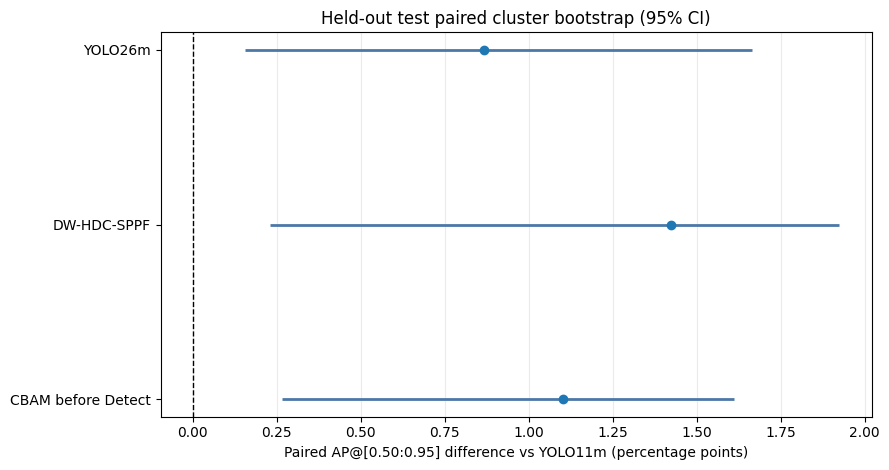

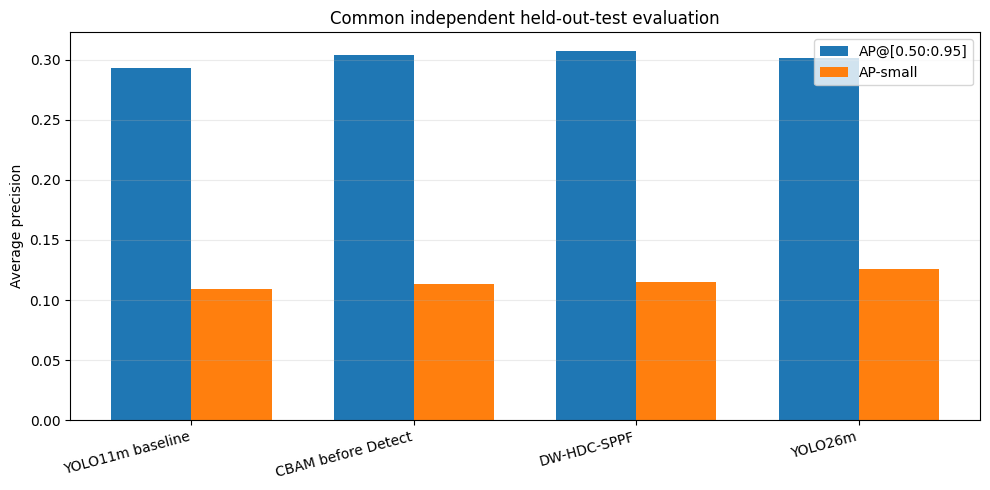

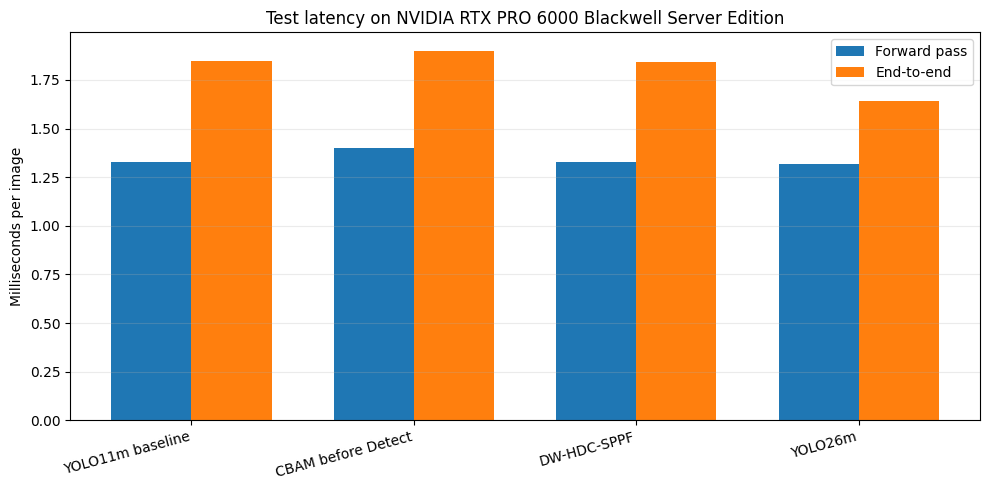

Saved figures to: /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis


In [ ]:
primary_summary = bootstrap_summary[
    bootstrap_summary["metric"].eq("AP_all")
].copy()
primary_summary = primary_summary.set_index("candidate").reindex(
    [candidate for candidate, _ in COMPARISONS]
).reset_index()

x = 100.0 * primary_summary["observed_delta"].to_numpy()
lower = 100.0 * primary_summary["ci_lower"].to_numpy()
upper = 100.0 * primary_summary["ci_upper"].to_numpy()
y = np.arange(len(primary_summary))

figure, axis = plt.subplots(figsize=(9, 4.8))
axis.hlines(y, lower, upper, color="#4c78a8", linewidth=2)
axis.plot(x, y, "o", color="#1f77b4")
axis.axvline(0, color="black", linewidth=1, linestyle="--")
axis.set_yticks(y, primary_summary["candidate"])
axis.set_xlabel("Paired AP@[0.50:0.95] difference vs YOLO11m (percentage points)")
axis.set_title(f"Held-out test paired cluster bootstrap ({CONFIDENCE_LEVEL:.0%} CI)")
axis.grid(axis="x", alpha=0.25)
figure.tight_layout()

bootstrap_figure = OUTPUT_DIR / "paired_ap_differences_95ci.png"
figure.savefig(bootstrap_figure, dpi=200, bbox_inches="tight")
plt.show()

accuracy_metrics = ["AP_all", "AP_small"]
accuracy_plot = point_estimates[
    point_estimates["metric"].isin(accuracy_metrics)
].copy()
accuracy_plot["model"] = pd.Categorical(
    accuracy_plot["model"], categories=MODEL_ORDER, ordered=True
)
accuracy_plot = accuracy_plot.sort_values(["model", "metric"])

figure, axis = plt.subplots(figsize=(10, 5))
width = 0.36
positions = np.arange(len(MODEL_ORDER))
for offset, metric in zip((-width / 2, width / 2), accuracy_metrics):
    values = (
        accuracy_plot[accuracy_plot["metric"].eq(metric)]
        .set_index("model")
        .reindex(MODEL_ORDER)["value"]
    )
    axis.bar(
        positions + offset,
        values,
        width,
        label=METRICS[metric],
    )
axis.set_xticks(positions, MODEL_ORDER, rotation=15, ha="right")
axis.set_ylabel("Average precision")
axis.set_title("Common independent held-out-test evaluation")
axis.legend()
axis.grid(axis="y", alpha=0.25)
figure.tight_layout()

accuracy_figure = OUTPUT_DIR / "common_test_accuracy.png"
figure.savefig(accuracy_figure, dpi=200, bbox_inches="tight")
plt.show()

if not missing_runtime.any():
    figure, axis = plt.subplots(figsize=(10, 5))
    positions = np.arange(len(MODEL_ORDER))
    axis.bar(
        positions - width / 2,
        runtime_table["inference_ms"],
        width,
        label="Forward pass",
    )
    axis.bar(
        positions + width / 2,
        runtime_table["end_to_end_ms"],
        width,
        label="End-to-end",
    )
    axis.set_xticks(positions, MODEL_ORDER, rotation=15, ha="right")
    axis.set_ylabel("Milliseconds per image")
    axis.set_title(f"Test latency on {TEST_GPU}")
    axis.legend()
    axis.grid(axis="y", alpha=0.25)
    figure.tight_layout()

    latency_figure = OUTPUT_DIR / "common_test_latency.png"
    figure.savefig(latency_figure, dpi=200, bbox_inches="tight")
    plt.show()

print("Saved figures to:", OUTPUT_DIR)

## 11) Interpretation boundaries

- The primary inference is the paired difference in **AP@[0.50:0.95]** relative to the matched YOLO11m baseline.
- A confidence interval entirely above zero supports a positive held-out transfer; entirely below zero supports a negative transfer; crossing zero is inconclusive.
- YOLO26m remains a **separate comparator**, not another YOLO11 ablation.
- Per-class results, AP50, AP75, and size-stratified metrics are secondary or descriptive unless already predeclared otherwise.
- Latency is directly comparable only because all four test runs use the same GPU, batch, precision, image size, and inference settings. It is reported descriptively rather than bootstrapped.
- Cluster-bootstrap intervals quantify uncertainty from the grouped test images. They do not quantify training-seed variability because every checkpoint was trained at seed 0.
- Do not retrain, retune thresholds, substitute candidates, or create a new model ranking from these test results.

In [ ]:
expected_outputs = [
    GROUP_MAP_FILE,
    OUTPUT_DIR / "prediction_validation_summary.csv",
    OUTPUT_DIR / "common_test_point_estimates.csv",
    OUTPUT_DIR / "common_test_per_class_ap.csv",
    OUTPUT_DIR / "runtime_and_complexity.csv",
    bootstrap_file,
    OUTPUT_DIR / "paired_cluster_bootstrap_summary.csv",
    OUTPUT_DIR / "paired_ap_differences_95ci.png",
    OUTPUT_DIR / "common_test_accuracy.png",
]
if not missing_runtime.any():
    expected_outputs.append(OUTPUT_DIR / "common_test_latency.png")

print("\n=============== COMMON TEST ANALYSIS OUTPUTS ===============")
for output in expected_outputs:
    status = "READY" if output.is_file() else "MISSING"
    print(f"{status:<7} | {output}")
print("============================================================")


=============== COMMON TEST ANALYSIS OUTPUTS ===============
READY   | /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/test_image_groups.csv
READY   | /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/prediction_validation_summary.csv
READY   | /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/common_test_point_estimates.csv
READY   | /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/common_test_per_class_ap.csv
READY   | /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/runtime_and_complexity.csv
READY   | /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/paired_cluster_bootstrap_draws_seed20260824_n2000.csv
READY   | /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/paired_cluster_bootstrap_summary.csv
READY   | /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/paired_ap_differences_95ci.png
READY   | /content/drive/MyDrive/UnderWaterYOLO11/common-test-analysis/common_test_accuracy.png
READY   

## 12) Terminate the current runtime

In [ ]:
from google.colab import runtime

print("✅ Common test analysis completed")
runtime.unassign()

✅ Common test analysis completed
